# EMIT Data Extraction: A Complete Guide

This notebook walks through the entire process of searching for, downloading,
and cataloging NASA **EMIT** (Earth Surface Mineral Dust Source Investigation)
imaging spectrometer data from the Earthdata archive.

## What is EMIT?

EMIT is a NASA imaging spectrometer mounted on the International Space Station.
It measures reflected sunlight across **285 spectral bands** (380–2500 nm) at
~60 m spatial resolution. Its primary mission is mapping mineral dust source
regions, but its hyperspectral data is valuable for many remote sensing
applications.

## What are PICS?

**Pseudo-Invariant Calibration Sites (PICS)** are desert regions in North Africa
whose surface reflectance is exceptionally stable over time. By repeatedly
measuring these sites, we can assess whether EMIT’s radiometric calibration
drifts — a critical check for any satellite instrument.

## What this notebook covers

| Section | Topic |
|---------|-------|
| 1 | Setup and imports |
| 2 | PICS site configuration |
| 3 | EMIT data products explained |
| 4 | Authenticating to NASA Earthdata |
| 5 | Searching for granules (single product) |
| 6 | Searching across all products |
| 7 | Inspecting search results and granule metadata |
| 8 | Downloading granules |
| 9 | Manifest generation for provenance tracking |
| 10 | Full extraction pipeline end-to-end |
| 11 | Next steps: what happens after extraction |

**Prerequisites:** A NASA Earthdata account (free at https://urs.earthdata.nasa.gov/).

---
## 1. Setup and Imports

We use a small set of standard libraries:

- **`earthaccess`** — NASA's official Python library for authenticating with
  Earthdata and searching/downloading satellite data products.
- **`geopandas`** — For reading PICS site polygons from the GeoPackage.
- **`json`** — For writing download manifests.
- **`pathlib.Path`** — Cross-platform filesystem paths.
- **`logging`** — Structured log output so we can trace what happened.

In [2]:
import json
import logging
import sys
from datetime import datetime
from pathlib import Path
from typing import Any

import geopandas as gpd
import earthaccess

# Put the project root on sys.path so we can import our own modules.
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Set up logging so library messages appear in the notebook.
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s  %(levelname)-8s  %(name)s  %(message)s",
)
logger = logging.getLogger("extraction_notebook")

print(f"earthaccess version: {earthaccess.__version__}")
print(f"Project root: {PROJECT_ROOT}")

earthaccess version: 0.18.0
Project root: C:\Users\huckr\Desktop\JPL\Code\EMIT


---
## 2. PICS Site Configuration

Site definitions are loaded from a **GeoPackage** containing one polygon
feature per PICS site. Each feature includes:

| Field | Description |
|-------|-------------|
| `site_name` | Human-readable site name (e.g. "Libya 4") |
| `geom` | Polygon geometry in EPSG:4326 (WGS 84) |
| `center_lat` | Latitude of the ROI center (decimal degrees N) |
| `center_lon` | Longitude of the ROI center (decimal degrees E) |
| `country` | Country where the site is located |
| `altitude_m` | Site elevation above sea level (m) |
| `utm_zone` | UTM zone number |
| `usable_area_km` | Usable area dimensions |
| `source` | USGS reference URL |

The polygon geometries are used directly in the Earthdata search — instead
of querying by a single point coordinate, we search for granules whose
swath footprint **intersects** the site polygon. This is more robust than a
point query because it captures any granule that overlaps the ROI, even if
the site center falls just outside a swath edge.

In [3]:
PICS_GPKG = Path(r"C:\Users\huckr\Desktop\JPL\Data\ROIs\northafrican_pics.gpkg")

sites_gdf = gpd.read_file(PICS_GPKG)

print(f"GeoPackage: {PICS_GPKG}")
print(f"Number of sites: {len(sites_gdf)}")
print(f"CRS: {sites_gdf.crs}\n")

# Display each site with key attributes.
print(f"{'Site Name':<16} {'Country':<14} {'Lat':>8} {'Lon':>8}  {'Altitude (m)':>12}")
print("-" * 65)
for _, row in sites_gdf.iterrows():
    print(
        f"{row['site_name']:<16} {row['country']:<14} "
        f"{row['center_lat']:>8.2f} {row['center_lon']:>8.2f}  "
        f"{row['altitude_m']:>12}"
    )

GeoPackage: C:\Users\huckr\Desktop\JPL\Data\ROIs\northafrican_pics.gpkg
Number of sites: 6
CRS: EPSG:4326

Site Name        Country             Lat      Lon  Altitude (m)
-----------------------------------------------------------------
Libya 4          Libya             28.55    23.39           118
Algeria 3        Algeria           30.32     7.66           245
Libya 1          Libya             24.42    13.35           648
Mauritania 1     Mauritania        19.40    -9.30           392
Mauritania 2     Mauritania        20.85    -8.78           384
Algeria 5        Algeria           31.02     2.23           530


### Selecting a site

We select a single PICS site by name from the GeoPackage. The polygon
geometry will be passed directly to `earthaccess.search_data()` as the
spatial query — replacing the single-point lookup used previously.

We'll use **Libya 4** throughout this notebook — it's the most widely used
PICS site.

In [3]:
SITE_NAME = "Libya 4"

site_row = sites_gdf[sites_gdf["site_name"] == SITE_NAME].iloc[0]
site_polygon = site_row.geometry

# Derive a filesystem-safe site ID for output filenames and directories.
SITE_ID = SITE_NAME.lower().replace(" ", "_")

# Extract the polygon's exterior coordinates as a list of (lon, lat) tuples.
# This is the format earthaccess.search_data(polygon=...) expects.
POLYGON_COORDS = list(site_polygon.exterior.coords)

print(f"Site: {site_row['site_name']}")
print(f"  Center:    {site_row['center_lat']:.2f}\u00b0N, {site_row['center_lon']:.2f}\u00b0E")
print(f"  Altitude:  {site_row['altitude_m']} m")
print(f"  UTM zone:  {site_row['utm_zone']}")
print(f"  Source:    {site_row['source']}")
print(f"\nPolygon bounds (west, south, east, north):")
bounds = site_polygon.bounds  # (minx, miny, maxx, maxy)
print(f"  ({bounds[0]:.4f}, {bounds[1]:.4f}, {bounds[2]:.4f}, {bounds[3]:.4f})")
print(f"Polygon vertices: {len(POLYGON_COORDS)}")

Site: Libya 4
  Center:    28.55°N, 23.39°E
  Altitude:  118 m
  UTM zone:  34
  Source:    https://calval.cr.usgs.gov/apps/libya-4

Polygon bounds (west, south, east, north):
  (22.8900, 28.0500, 23.8900, 29.0500)
Polygon vertices: 5


### Polygon geometry details

The polygon from the GeoPackage defines the full CEOS reference area for
this PICS site. Below we print its vertices and confirm the coordinate
reference system is WGS 84 (EPSG:4326), which is what Earthdata's CMR
expects for spatial queries.

In [4]:
print(f"CRS: {sites_gdf.crs}")
print(f"Geometry type: {site_polygon.geom_type}")
print(f"Area (sq degrees): {site_polygon.area:.4f}")
print(f"\nPolygon vertices (lon, lat):")
for i, (lon, lat) in enumerate(POLYGON_COORDS):
    print(f"  [{i}] ({lon:.4f}, {lat:.4f})")

CRS: EPSG:4326
Geometry type: Polygon
Area (sq degrees): 1.0000

Polygon vertices (lon, lat):
  [0] (23.8900, 28.0500)
  [1] (23.8900, 29.0500)
  [2] (22.8900, 29.0500)
  [3] (22.8900, 28.0500)
  [4] (23.8900, 28.0500)


---
## 3. EMIT Data Products

EMIT distributes its data as NetCDF4 files (one set of files per overpass,
called a *granule*). For temporal stability analysis, we need data from
two Earthdata **collections** and one bundled companion file:

| File | Earthdata Collection | Contents | Why we need it |
|------|---------------------|----------|----------------|
| **`*_RAD_*.nc`** | `EMITL1BRAD` | Top-of-atmosphere radiance (285 bands) | Raw sensor signal — the primary measurement for stability tracking |
| **`*_OBS_*.nc`** | *(bundled with L1B RAD)* | Observation geometry (10 bands) | Solar/view zenith angles — needed to normalize for illumination differences |
| **`*_RFL_*.nc`** | `EMITL2ARFL` | Surface reflectance + quality masks | Atmospherically corrected data and cloud/quality flags |

### The OBS file is bundled, not a separate collection

A common point of confusion: the observation geometry file (`*_OBS_*.nc`)
is **not** its own Earthdata collection. There is no `EMITL1BOBS` short name
to search for. Instead, the OBS file ships as a companion file *inside* each
`EMITL1BRAD` granule. When you download one L1B RAD granule, you get **two**
NetCDF4 files on disk:

```
  EMITL1BRAD granule (one search result)
       │
       ├── EMIT_L1B_RAD_*.nc   ← radiance data (285 bands)
       └── EMIT_L1B_OBS_*.nc   ← observation geometry (SZA, VZA, etc.)
```

Only **two** collections need to be searched: `EMITL1BRAD` and `EMITL2ARFL`.

In [5]:
# The two searchable EMIT collections on Earthdata.
# Note: the OBS geometry file is NOT a separate collection — it is bundled
# inside each EMITL1BRAD granule download (see explanation above).
EMIT_PRODUCTS = {
    "L1B_RAD": "EMITL1BRAD",
    "L2A_RFL": "EMITL2ARFL",
}

print("Searchable EMIT collections:")
print(f"{'Label':<12} {'Earthdata Short Name':<20} {'Description'}")
print("-" * 72)
descriptions = {
    "L1B_RAD": "L1B Radiance + bundled OBS geometry",
    "L2A_RFL": "L2A Reflectance + uncertainty + masks",
}
for label, short_name in EMIT_PRODUCTS.items():
    print(f"{label:<12} {short_name:<20} {descriptions[label]}")
print()
print("The OBS file (*_OBS_*.nc) arrives automatically with each L1B_RAD download.")

Searchable EMIT collections:
Label        Earthdata Short Name Description
------------------------------------------------------------------------
L1B_RAD      EMITL1BRAD           L1B Radiance + bundled OBS geometry
L2A_RFL      EMITL2ARFL           L2A Reflectance + uncertainty + masks

The OBS file (*_OBS_*.nc) arrives automatically with each L1B_RAD download.


---
## 4. Authenticating to NASA Earthdata

Before we can search or download data, we need to authenticate with NASA’s
Earthdata system. The `earthaccess.login()` function checks for credentials
in this order:

1. **Existing valid token** cached in `~/.earthaccess/`
2. **Credentials in `.netrc` / `_netrc`** (a standard file for storing
   machine credentials)
3. **Interactive prompt** — it will ask for your username and password

No credentials are ever stored in this repository.

In [6]:
def authenticate() -> None:
    """Authenticate to NASA Earthdata.

    Uses earthaccess.login() which checks, in order:
        1. Existing valid token in ~/.earthaccess/
        2. Credentials in .netrc / _netrc
        3. Interactive prompt

    No credentials are stored in this codebase.
    """
    earthaccess.login()
    logger.info("Authenticated to NASA Earthdata.")


authenticate()
print("Authentication successful.")

2026-06-20 20:47:09,209  INFO      earthaccess.auth  You're now authenticated with NASA Earthdata Login
2026-06-20 20:47:09,212  INFO      earthaccess.auth  Using token with expiration date 08/14/2026
2026-06-20 20:47:10,836  INFO      extraction_notebook  Authenticated to NASA Earthdata.


Authentication successful.


---
## 5. Searching for Granules (Single Product)

A **granule** is a single data file — one product from one overpass.
The `earthaccess.search_data()` function queries NASA's Common Metadata
Repository (CMR) to find granules matching our criteria:

- **`short_name`** — Which data product (e.g. `EMITL1BRAD`)
- **`polygon`** — A list of `(lon, lat)` vertices defining the ROI polygon.
  CMR returns every granule whose swath footprint **intersects** this polygon.
- **`temporal`** — A `(start, end)` date range

**Important:** `earthaccess` uses `(lon, lat)` order (GeoJSON convention),
not the `(lat, lon)` you might expect from everyday usage.

### Why polygon search instead of a point?

A point query checks whether a single coordinate falls inside a granule's
swath footprint. A polygon query checks whether the ROI *area* intersects
the swath. The polygon approach is more robust — it captures granules that
partially overlap the site, even when the center point falls just outside
the swath edge. This matters for EMIT because the ISS swath is narrow
(~80 km) and its ground track is irregular.

### ISS coverage is sparse

Unlike polar-orbiting satellites that follow a repeating ground track,
EMIT is mounted on the **International Space Station** (~51.6° inclination),
whose orbit precesses over time. This means:

- Coverage of any specific point is **irregular** — there is no fixed revisit
  cycle.
- A single-month search window can easily return **zero results** for a given
  location.
- To reliably find data, use a **wide date range** (6–12 months or more).

EMIT began science operations in **August 2022**, so the earliest possible
data starts around that date.

Let's start with a single product and a full-year window to see how the
search works.

In [7]:
def search_granules(
    short_name: str,
    polygon: list[tuple[float, float]],
    date_start: str,
    date_end: str,
) -> list:
    """Search Earthdata for EMIT granules intersecting a polygon and date range.

    Parameters
    ----------
    short_name : str
        Earthdata collection short_name, e.g. 'EMITL1BRAD'.
    polygon : list of (lon, lat) tuples
        Vertices of the ROI polygon (EPSG:4326).
    date_start, date_end : str
        ISO-8601 date strings, e.g. '2023-08-01'.

    Returns
    -------
    list
        earthaccess granule result objects.
    """
    results = earthaccess.search_data(
        short_name=short_name,
        polygon=polygon,
        temporal=(date_start, date_end),
    )
    logger.info(
        "Found %d granules for %s [%s to %s]",
        len(results), short_name, date_start, date_end,
    )
    return results

In [8]:
# Search for L2A Reflectance granules over Libya 4 for the full archive.
# A wide window is needed because ISS coverage is irregular — a single
# month may have zero overpasses at a given location.
DATE_START = "2022-08-01"
DATE_END = "2026-06-17"

rad_results = search_granules(
    short_name="EMITL2ARFL",
    polygon=POLYGON_COORDS,
    date_start=DATE_START,
    date_end=DATE_END,
)

print(f"\nFound {len(rad_results)} L2A Reflectance granule(s) for {site_row['site_name']}")
print(f"  Date range: {DATE_START} to {DATE_END}")
print(f"  Query:      polygon ({len(POLYGON_COORDS)} vertices)")

2026-06-18 10:06:40,982  INFO      earthaccess.api  Granules found: 78
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
2026-06-18 10:06:41,629  INFO      extraction_notebook  Found 78 granules for EMITL2ARFL [2022-08-01 to 2026-06-17]



Found 78 L2A Reflectance granule(s) for Libya 4
  Date range: 2022-08-01 to 2026-06-17
  Query:      polygon (5 vertices)


---
## 6. Searching Across All Products

For a complete overpass dataset, we need both searchable collections. The
`search_all_products()` function loops over `EMIT_PRODUCTS` and runs
a search for each one with the same polygon and date range.

The result is a dict keyed by product label:

```python
{
    "L1B_RAD": [granule, granule, ...],   # each download also yields an OBS file
    "L2A_RFL": [granule, granule, ...],
}
```

Ideally both products return the same number of granules (one per overpass),
but this is not always the case — some products may have gaps.

In [8]:
def search_all_products(
    polygon: list[tuple[float, float]],
    date_start: str,
    date_end: str,
) -> dict[str, list]:
    """Search for both EMIT collections at a site.

    Returns a dict keyed by product label (e.g. 'L1B_RAD') with lists
    of granule results.
    """
    results = {}
    for label, short_name in EMIT_PRODUCTS.items():
        results[label] = search_granules(
            short_name, polygon, date_start, date_end,
        )
    return results

In [10]:
all_results = search_all_products(POLYGON_COORDS, DATE_START, DATE_END)

# Summary table.
print(f"\nSearch results for {site_row['site_name']} ({DATE_START} to {DATE_END})")
print(f"{'Product':<12} {'Short Name':<16} {'Granules Found'}")
print("-" * 45)
total = 0
for label, granules in all_results.items():
    print(f"{label:<12} {EMIT_PRODUCTS[label]:<16} {len(granules)}")
    total += len(granules)
print("-" * 45)
print(f"{'Total':<29} {total}")

if total == 0:
    print(
        "\nNo granules found. Try a wider date range or verify that "
        "EMIT has coverage at this location during this period."
    )

2026-06-18 10:07:35,920  INFO      earthaccess.api  Granules found: 78
2026-06-18 10:07:36,382  INFO      extraction_notebook  Found 78 granules for EMITL1BRAD [2022-08-01 to 2026-06-17]
2026-06-18 10:07:36,607  INFO      earthaccess.api  Granules found: 78
2026-06-18 10:07:39,198  INFO      extraction_notebook  Found 78 granules for EMITL2ARFL [2022-08-01 to 2026-06-17]



Search results for Libya 4 (2022-08-01 to 2026-06-17)
Product      Short Name       Granules Found
---------------------------------------------
L1B_RAD      EMITL1BRAD       78
L2A_RFL      EMITL2ARFL       78
---------------------------------------------
Total                         156


---
## 7. Inspecting Search Results and Granule Metadata

Each granule object returned by `earthaccess.search_data()` wraps a
**UMM-G** (Unified Metadata Model for Granules) record from NASA’s CMR.
This is a rich JSON structure containing:

- **GranuleUR** — A unique identifier for the granule
- **CollectionReference** — Which product and version it belongs to
- **TemporalExtent** — Acquisition start/end times
- **SpatialExtent** — The geographic footprint of the swath
- **AdditionalAttributes** — Processing version, algorithm version, etc.
- **DataGranule** — File sizes, checksums, archive info
- **RelatedUrls** — Download links

Understanding this structure is important because we extract metadata from it
to build provenance manifests.

In [11]:
# Look at the first L1B RAD granule (if any were found).
if rad_results:
    granule = rad_results[0]

    # earthaccess granule objects support dict-like access.
    # The full UMM record is under the "umm" key.
    print("Top-level keys in the granule object:")
    if isinstance(granule, dict):
        print(f"  {list(granule.keys())}")
    else:
        # earthaccess DataGranule objects have a .dict() or .__dict__ method
        print(f"  Type: {type(granule).__name__}")
        # Access the underlying UMM structure
        try:
            print(f"  UMM keys: {list(granule['umm'].keys())}")
        except (KeyError, TypeError):
            print("  (Could not access UMM keys directly)")
else:
    print("No granules to inspect. Re-run with a date range that has coverage.")

Top-level keys in the granule object:
  ['meta', 'umm', 'size']


### Extracting provenance metadata

For reproducibility and traceability, we extract key metadata from each
granule. This function pulls the most important fields and handles
cases where certain fields may not be present (the UMM structure can
vary between providers and product versions).

In [9]:
def _extract_granule_metadata(granule) -> dict[str, Any]:
    """Pull provenance-relevant metadata from an earthaccess granule object.

    We capture the processing/software build version so that downstream
    analyses can flag granules processed with different algorithm versions.
    """
    meta: dict[str, Any] = {}

    # --- GranuleUR: unique identifier ---
    try:
        meta["granule_ur"] = granule["umm"]["GranuleUR"]
    except (KeyError, TypeError):
        meta["granule_ur"] = str(granule)

    # --- Collection info: product short name and version ---
    try:
        meta["collection"] = granule["umm"]["CollectionReference"]["ShortName"]
    except (KeyError, TypeError):
        meta["collection"] = None

    try:
        meta["version"] = granule["umm"]["CollectionReference"]["Version"]
    except (KeyError, TypeError):
        meta["version"] = None

    # --- PGEVersion / software build version ---
    # Lives in AdditionalAttributes; the key name varies by provider.
    try:
        attrs = granule["umm"].get("AdditionalAttributes", [])
        for attr in attrs:
            if attr.get("Name") in ("PGEVersion", "SOFTWARE_BUILD_VERSION"):
                meta["pge_version"] = attr["Values"][0]
                break
    except (KeyError, TypeError):
        pass
    if "pge_version" not in meta:
        meta["pge_version"] = None

    # --- Temporal extent: acquisition time window ---
    try:
        time_range = granule["umm"]["TemporalExtent"]["RangeDateTime"]
        meta["time_start"] = time_range.get("BeginningDateTime")
        meta["time_end"] = time_range.get("EndingDateTime")
    except (KeyError, TypeError):
        meta["time_start"] = None
        meta["time_end"] = None

    return meta

In [17]:
# Extract and display metadata for each found granule.
if rad_results:
    print("Metadata extracted from L1B RAD search results:\n")
    for i, g in enumerate(rad_results):
        meta = _extract_granule_metadata(g)
        print(f"Granule {i}:")
        for key, val in meta.items():
            print(f"  {key:<16} {val}")
        print()
else:
    print("No granules to extract metadata from.")

Metadata extracted from L1B RAD search results:

Granule 0:
  granule_ur       EMIT_L2A_RFL_001_20220823T105327_2223507_009
  collection       EMITL2ARFL
  version          001
  pge_version      010609
  time_start       2022-08-23T10:53:27Z
  time_end         2022-08-23T10:53:39Z

Granule 1:
  granule_ur       EMIT_L2A_RFL_001_20220827T091626_2223906_009
  collection       EMITL2ARFL
  version          001
  pge_version      010609
  time_start       2022-08-27T09:16:26Z
  time_end         2022-08-27T09:16:38Z

Granule 2:
  granule_ur       EMIT_L2A_RFL_001_20230302T071844_2306105_003
  collection       EMITL2ARFL
  version          001
  pge_version      010610
  time_start       2023-03-02T07:18:44Z
  time_end         2023-03-02T07:18:56Z

Granule 3:
  granule_ur       EMIT_L2A_RFL_001_20230425T095455_2311507_013
  collection       EMITL2ARFL
  version          001
  pge_version      010611
  time_start       2023-04-25T09:54:55Z
  time_end         2023-04-25T09:55:07Z

Granule 4:


### Why provenance metadata matters

When tracking instrument stability over months or years, it is critical
to know:

- **Collection version** — Did the processing algorithm change between
  granules? A jump in measured radiance could be a real instrument change
  or just a reprocessing artifact.
- **PGE version** — The specific software build that produced the data.
  Different builds may apply different calibration coefficients.
- **Acquisition time** — Solar geometry changes throughout the year.
  We need exact times to compute expected illumination angles.

Recording this metadata in a manifest file alongside the downloaded data
ensures that analyses remain reproducible even as new data versions are released.

---
## 8. Downloading Granules

Once we have search results, `earthaccess.download()` retrieves the actual
NetCDF4 files. Downloads are placed into a local directory, organized by
collection.

```
data/
  l1b_rad/                 <- L1B Radiance + bundled OBS geometry files
    EMIT_L1B_RAD_*.nc          (radiance)
    EMIT_L1B_OBS_*.nc          (observation geometry — arrives automatically)
  l2a_rfl/                 <- L2A Reflectance granules
    EMIT_L2A_RFL_*.nc
  manifest_libya_4.json    <- Provenance manifest
```

**Note:** Each `EMITL1BRAD` granule download produces **two** files — the
`*_RAD_*.nc` and its companion `*_OBS_*.nc`. There is no separate download
step for the OBS file. EMIT granules are large (hundreds of MB each). The
download function creates the destination directory if it doesn't exist.

In [10]:
DATA_DIR = PROJECT_ROOT / "data"


def download_granules(
    granules: list,
    dest_dir: Path = DATA_DIR,
) -> list[Path]:
    """Download a list of granules to a local directory.

    Parameters
    ----------
    granules : list
        earthaccess granule objects from a search call.
    dest_dir : Path
        Local directory to write files into.

    Returns
    -------
    list[Path]
        Paths to downloaded files.
    """
    dest_dir.mkdir(parents=True, exist_ok=True)
    files = earthaccess.download(granules, str(dest_dir))
    paths = [Path(f) for f in files]
    logger.info("Downloaded %d files to %s", len(paths), dest_dir)
    return paths


print(f"Data directory: {DATA_DIR}")
print(f"Directory exists: {DATA_DIR.exists()}")

Data directory: C:\Users\huckr\Desktop\JPL\Code\EMIT\data
Directory exists: True


### Download a small sample

To keep this demonstration manageable, we download only the **first granule**
of each collection (if any were found). In a real extraction run, you would
download all granules across a full date range.

For `L1B_RAD`, expect **two** files per granule in the output directory:
the radiance file (`*_RAD_*.nc`) and its bundled observation geometry file
(`*_OBS_*.nc`).

**Skip this cell** if you don't want to download data right now —
the manifest section below works with search results alone.

In [19]:
# Download the first granule of each collection (if results exist).
# Comment out this cell to skip the download.
downloaded_files = {}

for label, granules in all_results.items():
    if granules:
        product_dir = DATA_DIR / label.lower()
        # Only download the first granule for demonstration.
        sample = granules[:1]
        print(f"Downloading 1 {label} granule to {product_dir} ...")
        paths = download_granules(sample, product_dir)
        downloaded_files[label] = paths
        for p in paths:
            size_mb = p.stat().st_size / 1e6
            print(f"  -> {p.name}  ({size_mb:.1f} MB)")
    else:
        print(f"{label}: no granules to download")

# After L1B_RAD download, confirm that the bundled OBS file arrived.
rad_dir = DATA_DIR / "l1b_rad"
if rad_dir.exists():
    obs_files = sorted(rad_dir.glob("*_OBS_*.nc"))
    rad_files = sorted(rad_dir.glob("*_RAD_*.nc"))
    print(f"\nFiles in {rad_dir}:")
    print(f"  RAD files: {len(rad_files)}")
    print(f"  OBS files: {len(obs_files)}  (bundled with RAD granules)")
    if obs_files:
        for f in obs_files:
            print(f"    {f.name}  ({f.stat().st_size / 1e6:.1f} MB)")

print("\nDownload complete.")

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:838: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum(granule.size() for granule in granules) / 1024, 2)
2026-06-17 10:35:43,136  INFO      earthaccess.store  Getting 1 granules, approx download size: 1.83 GB


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

2026-06-17 10:42:38,387  INFO      extraction_notebook  Downloaded 2 files to C:\Users\huckr\Desktop\JPL\Code\EMIT\data\l1b_rad
2026-06-17 10:42:38,392  INFO      earthaccess.store  Getting 1 granules, approx download size: 3.49 GB


  -> EMIT_L1B_RAD_001_20220823T105327_2223507_009.nc  (1851.0 MB)
  -> EMIT_L1B_OBS_001_20220823T105327_2223507_009.nc  (108.7 MB)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

KeyboardInterrupt: 

---
## 9. Manifest Generation for Provenance Tracking

After searching (and optionally downloading), we write a **manifest** —
a JSON file that records what was found and key metadata for each granule.
This serves as a provenance record:

```json
{
  "site": "libya_4",
  "created_utc": "2024-01-15T12:30:00Z",
  "products": {
    "L1B_RAD": [
      {
        "granule_ur": "EMIT_L1B_RAD_...",
        "collection": "EMITL1BRAD",
        "version": "001",
        "pge_version": "1.2.0",
        "time_start": "2023-09-15T10:30:00Z",
        "time_end": "2023-09-15T10:31:00Z",
        "bundled_obs": "EMIT_L1B_OBS_*.nc"
      }
    ],
    "L2A_RFL": [ ... ]
  }
}
```

Each `L1B_RAD` entry includes a `bundled_obs` field recording the companion
OBS filename that shipped with that granule. The OBS file is not listed as
its own product because it is not a separately searchable collection — it
arrives automatically inside the `EMITL1BRAD` download.

The manifest is useful even for **dry runs** (search without download),
letting you inspect what data is available before committing to a
large download. In a dry run the `bundled_obs` field is set to a naming
pattern rather than an actual filename, since no files are on disk yet.

In [11]:
def write_manifest(
    all_granules: dict[str, list],
    site_id: str,
    dest_dir: Path = DATA_DIR,
) -> Path:
    """Write a JSON manifest of granules with provenance metadata.

    Parameters
    ----------
    all_granules : dict[str, list]
        Dict keyed by product label ('L1B_RAD', 'L2A_RFL') mapping to
        lists of earthaccess granule objects.
    site_id : str
        Identifier for the PICS site (used in the filename).
    dest_dir : Path
        Directory to write the manifest into.

    Returns
    -------
    Path
        Path to the written manifest file.
    """
    manifest: dict[str, Any] = {
        "site": site_id,
        "created_utc": datetime.utcnow().isoformat() + "Z",
        "products": {},
    }

    # The L1B_RAD download directory, used to find bundled OBS files.
    rad_dir = dest_dir / "l1b_rad"

    for label, granules in all_granules.items():
        entries = []
        for g in granules:
            meta = _extract_granule_metadata(g)

            # For L1B_RAD granules, record the companion OBS file.
            # The OBS file ships inside the same granule download; its
            # filename mirrors the RAD file with "OBS" replacing "RAD".
            if label == "L1B_RAD":
                obs_name = None
                granule_ur = meta.get("granule_ur", "")
                # Derive expected OBS filename from the granule UR.
                if "L1B_RAD" in granule_ur:
                    expected_obs = granule_ur.replace("L1B_RAD", "L1B_OBS")
                    # Check if the file actually exists on disk.
                    obs_path = rad_dir / (expected_obs + ".nc")
                    if obs_path.exists():
                        obs_name = obs_path.name
                    else:
                        # File not yet downloaded; record the expected pattern.
                        obs_name = expected_obs + ".nc"
                meta["bundled_obs"] = obs_name

            entries.append(meta)
        manifest["products"][label] = entries

    dest_dir.mkdir(parents=True, exist_ok=True)
    out_path = dest_dir / f"manifest_{site_id}.json"
    with open(out_path, "w") as f:
        json.dump(manifest, f, indent=2)

    logger.info("Wrote manifest to %s", out_path)
    return out_path

In [21]:
if total > 0:
    manifest_path = write_manifest(all_results, SITE_ID, DATA_DIR)
    print(f"Manifest written to: {manifest_path}\n")

    # Display the manifest contents.
    with open(manifest_path) as f:
        manifest_data = json.load(f)

    print(json.dumps(manifest_data, indent=2))
else:
    print("No search results — skipping manifest generation.")

C:\Users\huckr\AppData\Local\Temp\ipykernel_56936\1393772333.py:25: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_utc": datetime.utcnow().isoformat() + "Z",
2026-06-17 11:09:15,663  INFO      extraction_notebook  Wrote manifest to C:\Users\huckr\Desktop\JPL\Code\EMIT\data\manifest_libya_4.json


Manifest written to: C:\Users\huckr\Desktop\JPL\Code\EMIT\data\manifest_libya_4.json

{
  "site": "libya_4",
  "created_utc": "2026-06-17T18:09:15.657678Z",
  "products": {
    "L1B_RAD": [
      {
        "granule_ur": "EMIT_L1B_RAD_001_20220823T105327_2223507_009",
        "collection": "EMITL1BRAD",
        "version": "001",
        "pge_version": "010608",
        "time_start": "2022-08-23T10:53:27Z",
        "time_end": "2022-08-23T10:53:39Z",
        "bundled_obs": "EMIT_L1B_OBS_001_20220823T105327_2223507_009.nc"
      },
      {
        "granule_ur": "EMIT_L1B_RAD_001_20220827T091626_2223906_009",
        "collection": "EMITL1BRAD",
        "version": "001",
        "pge_version": "010608",
        "time_start": "2022-08-27T09:16:26Z",
        "time_end": "2022-08-27T09:16:38Z",
        "bundled_obs": "EMIT_L1B_OBS_001_20220827T091626_2223906_009.nc"
      },
      {
        "granule_ur": "EMIT_L1B_RAD_001_20230302T071844_2306105_003",
        "collection": "EMITL1BRAD",
      

---
## 10. Full Extraction Pipeline End-to-End

Now that we’ve walked through each piece, here is the complete pipeline
in a single function — exactly what the `scripts/run_extraction.py`
command-line tool does.

The pipeline has four stages:

```
  Authenticate   →   Search   →   Download   →   Write Manifest
       |               |              |                  |
   Earthdata       CMR query      NetCDF4 files      JSON provenance
   credentials     per product    to data/ dir        record
```

A `dry_run` flag lets you search and write a manifest without downloading.

In [12]:
def run_extraction(
    site_name: str,
    date_start: str,
    date_end: str,
    sites_gpkg: Path = PICS_GPKG,
    data_dir: Path = DATA_DIR,
    dry_run: bool = False,
) -> dict:
    """Run the full EMIT extraction pipeline for a PICS site.

    Parameters
    ----------
    site_name : str
        Site name from the GeoPackage (e.g. 'Libya 4').
    date_start, date_end : str
        ISO-8601 date strings defining the search window.
    sites_gpkg : Path
        Path to the PICS sites GeoPackage.
    data_dir : Path
        Root directory for downloads and manifest.
    dry_run : bool
        If True, search and write manifest but skip download.

    Returns
    -------
    dict
        Summary with keys 'site', 'results', 'manifest_path',
        and 'downloaded_files' (empty dict if dry_run).
    """
    # 1. Load the site polygon from the GeoPackage.
    gdf = gpd.read_file(sites_gpkg)
    match = gdf[gdf["site_name"] == site_name]
    if match.empty:
        available = ", ".join(gdf["site_name"].tolist())
        raise KeyError(f"Unknown site '{site_name}'. Available: {available}")
    row = match.iloc[0]
    polygon = list(row.geometry.exterior.coords)
    site_id = site_name.lower().replace(" ", "_")
    print(f"Site: {row['site_name']} ({row['center_lat']}, {row['center_lon']})")

    # 2. Authenticate.
    authenticate()

    # 3. Search both collections (L1B_RAD and L2A_RFL).
    print(f"Searching {date_start} to {date_end} ...")
    results = search_all_products(polygon, date_start, date_end)

    total = sum(len(v) for v in results.values())
    print(f"Total granules found: {total}")

    if total == 0:
        print("No granules found. Check site polygon and date range.")
        return {"site": site_name, "results": results,
                "manifest_path": None, "downloaded_files": {}}

    # 4. Download (unless dry run).
    #    L1B_RAD downloads produce two files each: *_RAD_*.nc and *_OBS_*.nc.
    dl_files = {}
    if dry_run:
        print("Dry run — skipping download.")
    else:
        for label, granules in results.items():
            if granules:
                product_dir = data_dir / label.lower()
                print(f"Downloading {len(granules)} {label} granule(s)...")
                dl_files[label] = download_granules(granules, product_dir)

    # 5. Write manifest (records OBS files as bundled with L1B_RAD).
    manifest_path = write_manifest(results, site_id, data_dir)
    print(f"Manifest: {manifest_path}")

    print("Done.")
    return {
        "site": site_name,
        "results": results,
        "manifest_path": manifest_path,
        "downloaded_files": dl_files,
    }

### Run as a dry run

To try the pipeline without downloading large files, set `dry_run=True`.
This searches CMR and writes the manifest, which you can inspect to see
what data is available.

In [16]:
# Dry run: search and generate manifest, but skip the download.
# Change dry_run to False to actually download the granules.
pipeline_result = run_extraction(
    site_name="Libya 4",
    date_start="2023-01-01",
    date_end="2023-12-31",
    dry_run=True,
)

Site: Libya 4 (28.55, 23.39)


2026-06-18 10:09:08,523  INFO      extraction_notebook  Authenticated to NASA Earthdata.


Searching 2023-01-01 to 2023-12-31 ...


2026-06-18 10:09:08,805  INFO      earthaccess.api  Granules found: 50
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
2026-06-18 10:09:20,828  INFO      extraction_notebook  Found 50 granules for EMITL1BRAD [2023-01-01 to 2023-12-31]
2026-06-18 10:09:21,068  INFO      earthaccess.api  Granules found: 50
2026-06-18 10:09:21,523  INFO      extraction_notebook  Found 50 granules for EMITL2ARFL [2023-01-01 to 2023-12-31]


Total granules found: 100
Dry run — skipping download.


NameError: name 'write_manifest' is not defined

---
## 11. Next Steps: What Happens After Extraction

Extraction gives us raw files on disk. The subsequent processing stages
(not yet implemented in this project) will:

### Stage 2: Orthorectification (GLT Application)

EMIT data is distributed in **raw swath** format — pixels are indexed by
crosstrack/downtrack position, not by geographic coordinates. Each granule
includes a **Geographic Lookup Table (GLT)** that maps `(ortho_row, ortho_col)`
to `(raw_row, raw_col)`. Applying the GLT resamples the swath onto a regular
lat/lon grid.

```
 Raw Swath (crosstrack x downtrack)    GLT     Orthorectified (lat x lon)
 ┌─────────────────┐            ┌───┐     ┌─────────────────┐
 │ ╭──────╮        │    ───>    │ N                 │
 │ │      │        │            │ ↑                 │
 │ │ data │        │   remap    │ │   data          │
 │ │      │        │            │ │   on regular    │
 │ ╰──────╯        │            │     lat/lon grid │
 └─────────────────┘            └─────────────────┘
```

### Stage 3: Geometry Extraction

The observation geometry file (`*_OBS_*.nc`) sits alongside each `*_RAD_*.nc`
in the `l1b_rad/` directory — it was downloaded automatically as part of the
same `EMITL1BRAD` granule. The geometry extraction step locates each
`*_OBS_*.nc` next to its companion `*_RAD_*.nc` and reads the observation
bands from it.

The OBS file stores geometry as an unlabeled multiband array. The known band
layout is:

| Band | Variable | Use |
|------|----------|-----|
| 0 | `path_length` | Sensor-to-ground distance |
| 1 | `to_sensor_azimuth` | Viewing direction |
| 2 | `to_sensor_zenith` | **VZA** — View Zenith Angle |
| 3 | `to_sun_azimuth` | Solar direction |
| 4 | `to_sun_zenith` | **SZA** — Solar Zenith Angle |
| 5 | `solar_phase` | Phase angle |
| 6 | `slope` | Terrain slope |
| 7 | `aspect` | Terrain aspect |
| 8 | `cosine(i)` | Cosine of incidence angle |
| 9 | `UTC_time` | Acquisition time per pixel |

SZA and VZA are needed to normalize radiance measurements — the same surface
viewed at different sun/sensor angles will produce different radiance values.

### Stage 4: ROI Statistics

After orthorectification, we clip the data to the PICS region of interest
(e.g., 10 km square centered on Libya 4), apply quality masks to exclude
clouds and bad pixels, and compute per-band spatial statistics (mean,
standard deviation, pixel count). These time series of per-band means
are the final product used to assess temporal stability.

```
Extraction  →  Orthorectify  →  Extract Geometry  →  ROI Stats  →  Time Series
(this         (apply GLT)     (SZA/VZA from        (per-band     (stability
 notebook)                     *_OBS_*.nc next       spatial       assessment)
                               to each *_RAD_*.nc)   mean)
```

See the `explore_granule.ipynb` notebook for hands-on inspection of
downloaded granule file structures.

---
## 12. EMIT Data Availability Across All PICS Sites

Before downloading any data, it is useful to survey what EMIT coverage
exists for **all six** PICS sites across the full mission timeline. This
section searches both collections (`EMITL1BRAD` and `EMITL2ARFL`) for
every site in the GeoPackage and visualizes temporal coverage in a single
figure.

Each vertical bar represents one granule. Bars are colored by the
**granule-level cloud cover** reported in CMR metadata (the same metadata
field that `earthaccess.search_data(cloud_cover=...)` filters on):

- **Green** — cloud cover ≤ 20 %
- **Red** — cloud cover > 20 %
- **Gray** — cloud cover not reported in CMR

Note that this is a *scene-wide* cloud cover estimate, not pixel-level
masking over the PICS polygon specifically.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Full EMIT mission date range.
DATE_START_ALL = "2022-08-01"
DATE_END_ALL = "2023-05-28"
CLOUD_THRESHOLD = 20  # percent

# Search every site x product combination and extract date + cloud cover.
# Structure: {site_name: {product_label: [(datetime, cloud_cover), ...]}}
availability = {}

for _, row in sites_gdf.iterrows():
    site_name = row["site_name"]
    polygon = list(row.geometry.exterior.coords)
    availability[site_name] = {}

    for label, short_name in EMIT_PRODUCTS.items():
        results = search_granules(
            short_name, polygon, DATE_START_ALL, DATE_END_ALL,
        )
        granule_info = []
        for g in results:
            # Parse acquisition datetime from UMM temporal extent.
            try:
                time_str = g["umm"]["TemporalExtent"]["RangeDateTime"][
                    "BeginningDateTime"
                ]
                # Strip fractional seconds if present, then parse.
                time_str = time_str.rstrip("Z").split(".")[0]
                dt = datetime.strptime(time_str, "%Y-%m-%dT%H:%M:%S")
            except (KeyError, TypeError, ValueError):
                continue

            # Granule-level cloud cover from CMR metadata (same field
            # that earthaccess.search_data(cloud_cover=...) filters on).
            cloud_cover = g["umm"].get("CloudCover")

            granule_info.append((dt, cloud_cover))

        availability[site_name][label] = granule_info

    n_rad = len(availability[site_name]["L1B_RAD"])
    n_rfl = len(availability[site_name]["L2A_RFL"])
    print(f"{site_name:<16}  L1B_RAD: {n_rad:>3}    L2A_RFL: {n_rfl:>3}")

# --- Cloud cover breakdown per site and product ---
print("\n")
print(f"{'Site':<16} {'Product':<10} {'Total':>6} {'CC<=20%':>8} {'CC>20%':>8} {'CC N/A':>8}")
print("-" * 60)
for site_name in sites_gdf["site_name"]:
    for label in EMIT_PRODUCTS:
        entries = availability[site_name][label]
        n_total = len(entries)
        n_clear = sum(1 for _, cc in entries if cc is not None and cc <= CLOUD_THRESHOLD)
        n_cloudy = sum(1 for _, cc in entries if cc is not None and cc > CLOUD_THRESHOLD)
        n_undef = sum(1 for _, cc in entries if cc is None)
        print(f"{site_name:<16} {label:<10} {n_total:>6} {n_clear:>8} {n_cloudy:>8} {n_undef:>8}")
    print()

2026-06-20 20:48:23,237  INFO      earthaccess.api  Granules found: 25
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
2026-06-20 20:48:23,646  INFO      extraction_notebook  Found 25 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]
2026-06-20 20:48:23,854  INFO      earthaccess.api  Granules found: 25
2026-06-20 20:48:24,357  INFO      extraction_notebook  Found 25 granules for EMITL2ARFL [2022-08-01 to 2023-05-28]


Libya 4           L1B_RAD:  25    L2A_RFL:  25


2026-06-20 20:48:24,733  INFO      earthaccess.api  Granules found: 15
2026-06-20 20:48:25,120  INFO      extraction_notebook  Found 15 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]
2026-06-20 20:48:25,362  INFO      earthaccess.api  Granules found: 15
2026-06-20 20:48:25,719  INFO      extraction_notebook  Found 15 granules for EMITL2ARFL [2022-08-01 to 2023-05-28]


Algeria 3         L1B_RAD:  15    L2A_RFL:  15


2026-06-20 20:48:25,958  INFO      earthaccess.api  Granules found: 10
2026-06-20 20:48:26,335  INFO      extraction_notebook  Found 10 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]
2026-06-20 20:48:26,586  INFO      earthaccess.api  Granules found: 10
2026-06-20 20:48:26,988  INFO      extraction_notebook  Found 10 granules for EMITL2ARFL [2022-08-01 to 2023-05-28]


Libya 1           L1B_RAD:  10    L2A_RFL:  10


2026-06-20 20:48:27,234  INFO      earthaccess.api  Granules found: 18
2026-06-20 20:48:27,589  INFO      extraction_notebook  Found 18 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]
2026-06-20 20:48:27,817  INFO      earthaccess.api  Granules found: 18
2026-06-20 20:48:28,209  INFO      extraction_notebook  Found 18 granules for EMITL2ARFL [2022-08-01 to 2023-05-28]


Mauritania 1      L1B_RAD:  18    L2A_RFL:  18


2026-06-20 20:48:28,437  INFO      earthaccess.api  Granules found: 8
2026-06-20 20:48:28,786  INFO      extraction_notebook  Found 8 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]
2026-06-20 20:48:29,029  INFO      earthaccess.api  Granules found: 8
2026-06-20 20:48:29,418  INFO      extraction_notebook  Found 8 granules for EMITL2ARFL [2022-08-01 to 2023-05-28]


Mauritania 2      L1B_RAD:   8    L2A_RFL:   8


2026-06-20 20:48:29,646  INFO      earthaccess.api  Granules found: 25
2026-06-20 20:48:30,065  INFO      extraction_notebook  Found 25 granules for EMITL1BRAD [2022-08-01 to 2023-05-28]


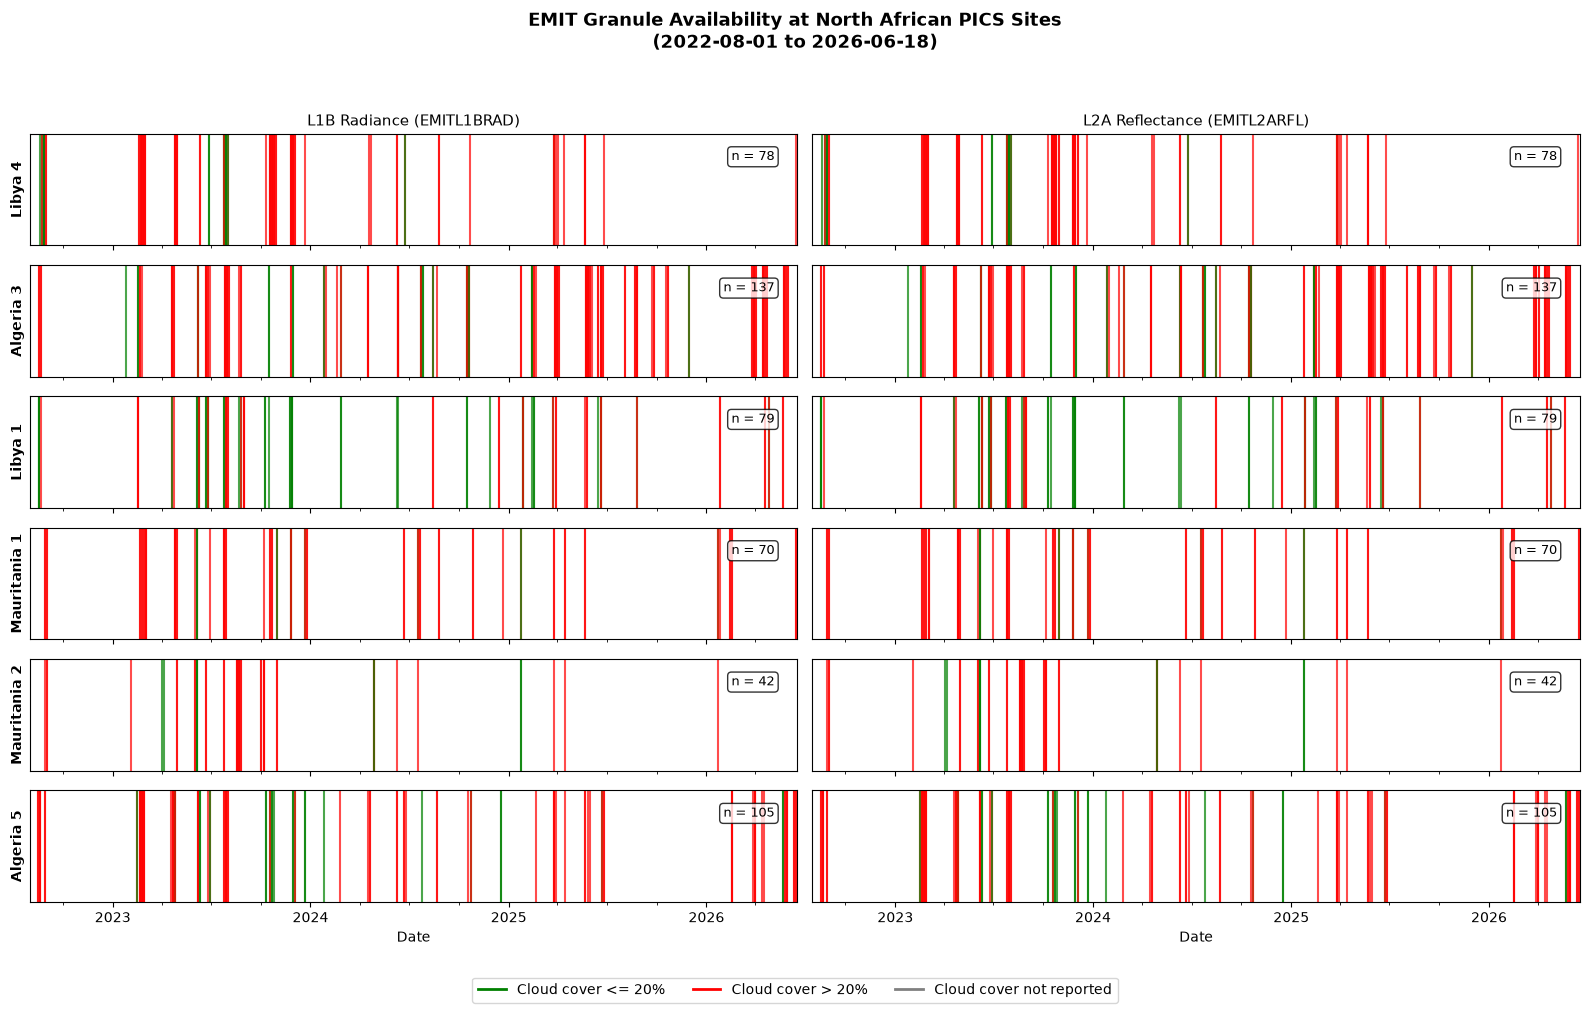

In [20]:
site_names = sites_gdf["site_name"].tolist()
product_labels = list(EMIT_PRODUCTS.keys())
product_titles = {
    "L1B_RAD": "L1B Radiance (EMITL1BRAD)",
    "L2A_RFL": "L2A Reflectance (EMITL2ARFL)",
}

fig, axes = plt.subplots(
    len(site_names), len(product_labels),
    figsize=(16, 10),
    sharex=True,
    sharey=True,
)

x_start = datetime(2022, 8, 1)
x_end = datetime(2026, 6, 18)

for row_idx, site_name in enumerate(site_names):
    for col_idx, label in enumerate(product_labels):
        ax = axes[row_idx, col_idx]
        granule_info = availability[site_name][label]

        for dt, cc in granule_info:
            if cc is None:
                color = "gray"
            elif cc > CLOUD_THRESHOLD:
                color = "red"
            else:
                color = "green"
            ax.axvline(dt, color=color, alpha=0.7, linewidth=1.5)

        # Site name on the left column only.
        if col_idx == 0:
            ax.set_ylabel(site_name, fontsize=10, fontweight="bold")

        # Column titles on the top row only.
        if row_idx == 0:
            ax.set_title(product_titles[label], fontsize=11)

        ax.set_xlim(x_start, x_end)
        ax.yaxis.set_ticks([])

        # Granule count annotation.
        n = len(granule_info)
        ax.text(
            0.97, 0.85, f"n = {n}",
            transform=ax.transAxes, fontsize=9, ha="right", va="top",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8),
        )

# Format x-axis on the bottom row.
for ax in axes[-1, :]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_xlabel("Date")

# Legend.
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color="green", linewidth=2,
           label=f"Cloud cover <= {CLOUD_THRESHOLD}%"),
    Line2D([0], [0], color="red", linewidth=2,
           label=f"Cloud cover > {CLOUD_THRESHOLD}%"),
    Line2D([0], [0], color="gray", linewidth=2,
           label="Cloud cover not reported"),
]
fig.legend(
    handles=legend_elements, loc="lower center", ncol=3, fontsize=10,
    frameon=True, bbox_to_anchor=(0.5, -0.02),
)

fig.suptitle(
    "EMIT Granule Availability at North African PICS Sites\n"
    f"({DATE_START_ALL} to {DATE_END_ALL})",
    fontsize=13, fontweight="bold",
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Granule-level detail for a single site

The table above summarizes cloud cover counts, but sometimes you need to
see exactly **which** granules are cloudy and when they were acquired.
The cell below queries both EMIT collections for a single PICS site and
date range, then prints every granule with its acquisition time and
cloud cover percentage.

Edit `QUERY_SITE` and the date strings to inspect a different site or
time window.

In [25]:
# ---- User-configurable parameters ----
QUERY_SITE = "Libya 4"
QUERY_DATE_START = "2022-08-01"
QUERY_DATE_END = "2022-08-31"
# ----------------------------------------

# Look up the site polygon.
query_row = sites_gdf[sites_gdf["site_name"] == QUERY_SITE].iloc[0]
query_polygon = list(query_row.geometry.exterior.coords)

print(f"Granule detail for {QUERY_SITE}  ({QUERY_DATE_START} to {QUERY_DATE_END})\n")

for label, short_name in EMIT_PRODUCTS.items():
    results = search_granules(
        short_name, query_polygon, QUERY_DATE_START, QUERY_DATE_END,
    )

    print(f"--- {label} ({short_name}) --- {len(results)} granule(s)")
    print(f"  {'#':<4} {'Acquisition (UTC)':<24} {'Cloud Cover':>12}  GranuleUR")
    print(f"  {'-'*4} {'-'*24} {'-'*12}  {'-'*50}")

    for i, g in enumerate(results):
        # Acquisition time
        try:
            time_str = g["umm"]["TemporalExtent"]["RangeDateTime"][
                "BeginningDateTime"
            ]
            time_str_clean = time_str.rstrip("Z").split(".")[0]
            dt = datetime.strptime(time_str_clean, "%Y-%m-%dT%H:%M:%S")
            dt_display = dt.strftime("%Y-%m-%d %H:%M:%S")
        except (KeyError, TypeError, ValueError):
            dt_display = "N/A"

        # Cloud cover
        cc = g["umm"].get("CloudCover")
        cc_display = f"{cc:.1f}%" if cc is not None else "N/A"

        # GranuleUR
        try:
            granule_ur = g["umm"]["GranuleUR"]
        except (KeyError, TypeError):
            granule_ur = "?"

        print(f"  {i:<4} {dt_display:<24} {cc_display:>12}  {granule_ur}")

    print()

Granule detail for Libya 4  (2022-08-01 to 2022-08-31)



2026-06-18 11:25:48,313  INFO      earthaccess.api  Granules found: 8
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
2026-06-18 11:25:48,808  INFO      extraction_notebook  Found 8 granules for EMITL1BRAD [2022-08-01 to 2022-08-31]


--- L1B_RAD (EMITL1BRAD) --- 8 granule(s)
  #    Acquisition (UTC)         Cloud Cover  GranuleUR
  ---- ------------------------ ------------  --------------------------------------------------
  0    2022-08-19 12:31:22              1.0%  EMIT_L1B_RAD_001_20220819T123122_2223108_008
  1    2022-08-23 10:53:27              7.0%  EMIT_L1B_RAD_001_20220823T105327_2223507_009
  2    2022-08-23 10:53:39             23.0%  EMIT_L1B_RAD_001_20220823T105339_2223507_010
  3    2022-08-27 09:16:14             19.0%  EMIT_L1B_RAD_001_20220827T091614_2223906_008
  4    2022-08-27 09:16:26              9.0%  EMIT_L1B_RAD_001_20220827T091626_2223906_009
  5    2022-08-27 09:16:38             20.0%  EMIT_L1B_RAD_001_20220827T091638_2223906_010
  6    2022-08-31 07:39:45            100.0%  EMIT_L1B_RAD_001_20220831T073945_2224305_006
  7    2022-08-31 07:39:57            100.0%  EMIT_L1B_RAD_001_20220831T073957_2224305_007



2026-06-18 11:25:49,102  INFO      earthaccess.api  Granules found: 8
2026-06-18 11:25:49,617  INFO      extraction_notebook  Found 8 granules for EMITL2ARFL [2022-08-01 to 2022-08-31]


--- L2A_RFL (EMITL2ARFL) --- 8 granule(s)
  #    Acquisition (UTC)         Cloud Cover  GranuleUR
  ---- ------------------------ ------------  --------------------------------------------------
  0    2022-08-19 12:31:22              1.0%  EMIT_L2A_RFL_001_20220819T123122_2223108_008
  1    2022-08-23 10:53:27              7.0%  EMIT_L2A_RFL_001_20220823T105327_2223507_009
  2    2022-08-23 10:53:39             23.0%  EMIT_L2A_RFL_001_20220823T105339_2223507_010
  3    2022-08-27 09:16:14             19.0%  EMIT_L2A_RFL_001_20220827T091614_2223906_008
  4    2022-08-27 09:16:26              9.0%  EMIT_L2A_RFL_001_20220827T091626_2223906_009
  5    2022-08-27 09:16:38             20.0%  EMIT_L2A_RFL_001_20220827T091638_2223906_010
  6    2022-08-31 07:39:45            100.0%  EMIT_L2A_RFL_001_20220831T073945_2224305_006
  7    2022-08-31 07:39:57            100.0%  EMIT_L2A_RFL_001_20220831T073957_2224305_007



2026-06-18 11:32:12,726  INFO      earthaccess.api  Granules found: 10
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
2026-06-18 11:32:13,157  INFO      extraction_notebook  Found 10 granules for EMITL2ARFL [2023-10-01 to 2023-11-30]


Mauritania 1: 10 L2A_RFL granule(s), 2023-10-01 to 2023-11-30


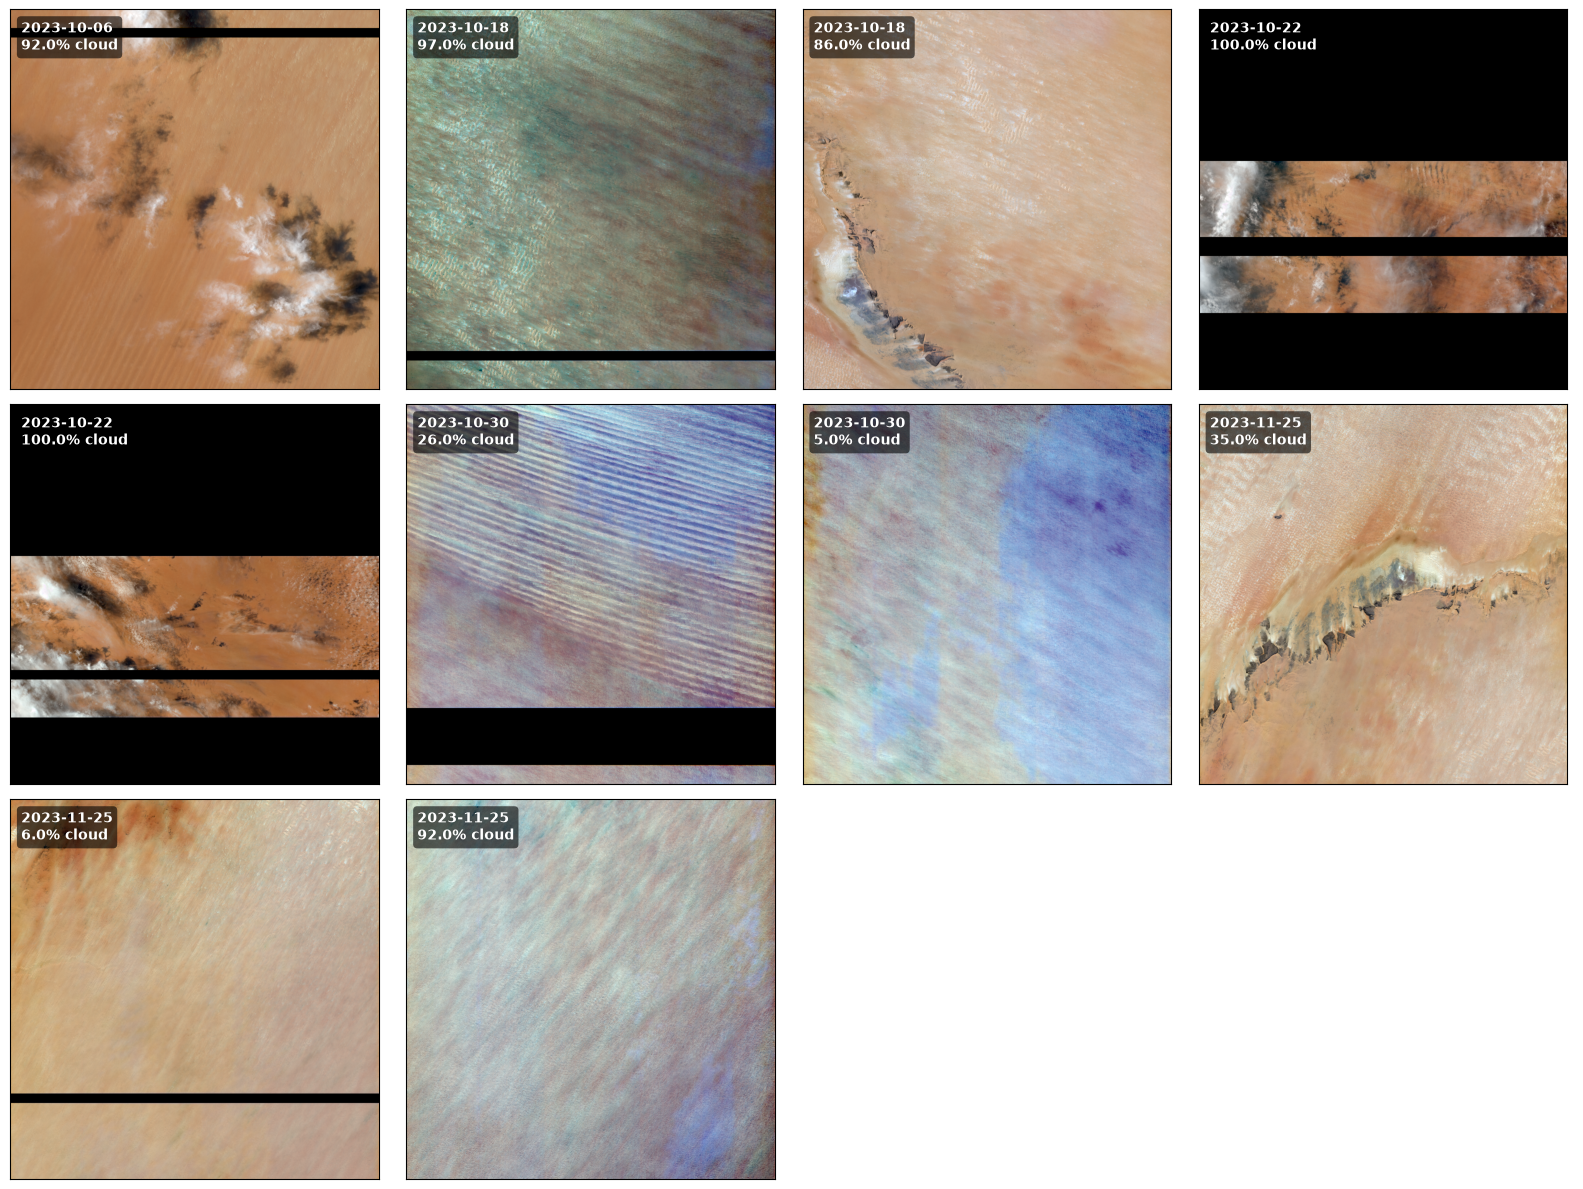

In [26]:
import io
import math
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt

# ---- User-configurable parameters ----
QUICKLOOK_SITE = "Mauritania 1"
QUICKLOOK_DATE_START = "2023-10-01"
QUICKLOOK_DATE_END = "2023-11-30"
QUICKLOOK_PRODUCT = "L2A_RFL"   # key into EMIT_PRODUCTS; L2A carries the RGB quicklook
N_COLS = 4                       # grid width
# ----------------------------------------

short_name = EMIT_PRODUCTS[QUICKLOOK_PRODUCT]

# Site polygon (same lookup pattern as the detail script)
query_row = sites_gdf[sites_gdf["site_name"] == QUICKLOOK_SITE].iloc[0]
query_polygon = list(query_row.geometry.exterior.coords)

results = search_granules(short_name, query_polygon, QUICKLOOK_DATE_START, QUICKLOOK_DATE_END)
print(f"{QUICKLOOK_SITE}: {len(results)} {QUICKLOOK_PRODUCT} granule(s), "
      f"{QUICKLOOK_DATE_START} to {QUICKLOOK_DATE_END}")

# Authenticated HTTPS session so browse PNGs load whether or not they're public.
# (Assumes earthaccess.login() was already run earlier in the notebook.)
session = earthaccess.get_requests_https_session()


def get_browse_url(g):
    """First browse/quicklook PNG URL for a granule, or None."""
    try:
        viz = g.dataviz_links()
        for u in viz:
            if u.lower().endswith(".png"):
                return u
        if viz:
            return viz[0]
    except (AttributeError, TypeError):
        pass
    # Fallback: parse RelatedUrls straight out of the UMM record
    try:
        for r in g["umm"].get("RelatedUrls", []):
            url = r.get("URL", "")
            if r.get("Type", "").upper().endswith("VISUALIZATION") or url.lower().endswith(".png"):
                return url
    except (KeyError, TypeError):
        pass
    return None


def get_cloud_cover(g):
    return g["umm"].get("CloudCover")


def get_acq_date(g):
    try:
        t = g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]
        t = t.rstrip("Z").split(".")[0]
        return datetime.strptime(t, "%Y-%m-%dT%H:%M:%S").strftime("%Y-%m-%d")
    except (KeyError, TypeError, ValueError):
        return "date N/A"


# Gather previews: (image_array_or_None, date_str, cloud_cover)
previews = []
for g in results:
    url = get_browse_url(g)
    img = None
    if url is not None:
        try:
            resp = session.get(url, timeout=60)
            resp.raise_for_status()
            img = plt.imread(io.BytesIO(resp.content), format="png")
        except Exception as e:
            print(f"  could not load browse for {get_acq_date(g)}: {e}")
    previews.append((img, get_acq_date(g), get_cloud_cover(g)))

# Plot grid
n = len(previews)
if n == 0:
    print("No granules to display.")
else:
    n_cols = min(N_COLS, n)
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = np.array(axes).reshape(-1)  # flatten, robust to single-row/single-cell grids

    for ax, (img, date_str, cc) in zip(axes, previews):
        if img is not None:
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, "no browse\nimage", ha="center", va="center",
                    transform=ax.transAxes, color="gray")
        cc_text = f"{cc:.1f}% cloud" if cc is not None else "cloud N/A"
        ax.text(
            0.03, 0.97, f"{date_str}\n{cc_text}",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=10, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.6, edgecolor="none"),
        )
        ax.set_xticks([])
        ax.set_yticks([])

    for ax in axes[n:]:   # hide any unused cells
        ax.axis("off")

    plt.tight_layout()
    plt.show()